# Aggregated "super cell" experiment

In [1]:
# 1 — Paths and settings for the single-cluster aggregation pilot.
from pathlib import Path
from datetime import datetime, timezone
import gc
import gzip
import hashlib
import importlib.metadata
import importlib.util
import json
import platform
import sys
import time

import anndata as ad
import numpy as np
import pandas as pd
from scipy import sparse
from scipy.io import mmread
from threadpoolctl import threadpool_limits
import torch
from IPython.display import display

ROOT = Path.home() / "scgpt-cna"
LAB_ROOT = Path("/home/akash1/projects/rrg-tperkins/dgladish/Projects/MSc/benchmarking_spatial_scale")
META = LAB_ROOT / "metadata/sample_md.tsv"
GDC_ROOT = LAB_ROOT / "GDC-data"
MODEL = ROOT / "models/whole-human"
HELPER = ROOT / "notebooks/scgpt_session/scgpt_session.py"
HISTORICAL = ROOT / "sanity_check/reference_4068d67/scgpt"
CENSUS_ANNOTATION = ROOT / "sanity_check/data/census_proximal_tubule_256/reference_raw.h5ad"

# One specimen; choose the cluster using size, before inspecting aggregation performance.
SAMPLE_IDS = ["C3N-00148-01"]
SOURCE_SAMPLE_ID = SAMPLE_IDS[0]


# If automatic discovery finds multiple matrices, explicitly set a directory here.
MATRIX_DIR_OVERRIDES = {}       # {"sample-id": Path("/absolute/path/to/mex_directory")}
COPYKAT_OVERRIDES = {}         # Optional: {"sample-id": Path("/absolute/path/to/prediction.txt")}

MODE = "pilot"                # Change to "full" after checking the pilot.
assert MODE in {"pilot", "full"}
SPLIT_SEED = 42
TARGET_POOLS_PER_SPLIT = 32
MIN_POOLS_PER_SPLIT = 16
POOL_SIZES_REQUESTED = [1, 5, 10]
POOL_SEED = 42
CLUSTER_OVERRIDE = None  # Optional explicit Seurat cluster ID (string).
N_REFERENCE = TARGET_POOLS_PER_SPLIT
N_EVALUATION = TARGET_POOLS_PER_SPLIT
MASK_FRACTION = 0.25
MASK_SEEDS = [42] if MODE == "pilot" else [42, 43, 44, 45]
MAX_EVALUATED = 8 if MODE == "pilot" else N_EVALUATION
ACTIVE_SAMPLE_IDS = SAMPLE_IDS
SEURAT_FILE = ROOT / "measurement_analysis" / SOURCE_SAMPLE_ID / "gdc_secondary_analysis/seurat.analysis.tsv"
RUN_SHUFFLED = True
SAVE_QUERY_PREDICTIONS = True  # Compressed per-mask files; no dense expression export.
N_THREADS = 4
torch.set_num_threads(N_THREADS)

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ") + "_" + MODE
RUN_DIR = ROOT / "aggregation_pilot/results" / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)

required = [META, SEURAT_FILE, HELPER, HISTORICAL / "preprocess.py",
            HISTORICAL / "data_collator.py", CENSUS_ANNOTATION]
required += [MODEL / f for f in ["args.json", "vocab.json", "best_model.pt"]]
for path in required:
    assert path.is_file(), f"Required existing file not found: {path}"
print("Python:", sys.executable)
print("PyTorch:", torch.__version__, "| threads:", torch.get_num_threads())
print("Mode:", MODE, "| active specimens:", ACTIVE_SAMPLE_IDS)
print("Output:", RUN_DIR)

RESULTS_ROOT = ROOT / "aggregation_pilot/results"
print("Seurat metadata:", SEURAT_FILE)


Python: /home/akash1/scgpt-cna/.venv-scgpt/bin/python
PyTorch: 2.2.2+cpu | threads: 4
Mode: pilot | active specimens: ['C3N-00148-01']
Output: /home/akash1/scgpt-cna/aggregation_pilot/results/20261110T180438530299Z_pilot
Seurat metadata: /home/akash1/scgpt-cna/measurement_analysis/C3N-00148-01/gdc_secondary_analysis/seurat.analysis.tsv


In [2]:
# 2 — Pin the preprocessing binding and load every checkpoint tensor strictly.
def import_file(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    assert Path(module.__file__).resolve() == Path(path).resolve()
    return module

session = import_file("multicase_verified_session", HELPER)
historical = import_file("multicase_historical_preprocess", HISTORICAL / "preprocess.py")
historical_collator = import_file(
    "scgpt._multicase_historical_collator", HISTORICAL / "data_collator.py"
)
historical_collator.binning = historical.binning
assert historical_collator.binning is historical.binning
assert historical._digitize.__defaults__ == ("one",), "Unexpected tie rule."

model, loaded_vocab, config = session.load_model(MODEL)
model = model.cpu().eval()
vocab = loaded_vocab.get_stoi()
assert config["n_bins"] == 51 and config["max_seq_len"] == 1200
pad_id = vocab[config.get("pad_token", "<pad>")]
cls_id = vocab["<cls>"]
pad_value = config.get("pad_value", -2)
collator = historical_collator.DataCollator(
    do_padding=True, pad_token_id=pad_id, pad_value=pad_value,
    do_mlm=True, do_binning=True, mlm_probability=MASK_FRACTION,
    mask_value=config.get("mask_value", -1), max_length=config["max_seq_len"],
    sampling=True, keep_first_n_tokens=1, data_style="both",
)
print("Helper:", session.__file__)
print("Historical tie rule:", historical._digitize.__defaults__)

def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(8 * 1024**2), b""):
            digest.update(block)
    return digest.hexdigest()

run_manifest = {
    "run_id": RUN_ID, "mode": MODE, "sample_ids": ACTIVE_SAMPLE_IDS,
    "split_seed": SPLIT_SEED, "n_reference": N_REFERENCE,
    "n_evaluation_reserved": N_EVALUATION, "n_evaluated": MAX_EVALUATED,
    "mask_seeds": MASK_SEEDS, "mask_fraction": MASK_FRACTION,
    "run_shuffled": RUN_SHUFFLED, "config": config,
    "helper_path": str(HELPER), "helper_sha256": sha256(HELPER),
    "checkpoint_sha256": sha256(MODEL / "best_model.pt"),
    "vocab_sha256": sha256(MODEL / "vocab.json"),
    "historical_commit": "4068d67caaac1e28d56964da68e0214817e38428",
    "historical_preprocess_sha256": sha256(HISTORICAL / "preprocess.py"),
    "historical_collator_sha256": sha256(HISTORICAL / "data_collator.py"),
    "census_annotation_path": str(CENSUS_ANNOTATION),
    "versions": {p: importlib.metadata.version(p) for p in
                 ["torch", "scgpt", "anndata", "numpy", "scipy", "pandas"]},
    "python": sys.version, "platform": platform.platform(),
    "baseline_scope": "Separate reference aggregates fitted independently at each pool size; positive-gene bin means",
    "qc_policy": "No new biological QC exclusions; require enough detected model genes for >=1 query",
    "limitations": [
        "Exploratory aggregation in one cluster of one previously explored specimen",
        "Only detected genes are queried; zero measurements are not evaluated",
        "Full-profile quantile boundaries use hidden expression values",
        "CopyKAT categories are predictions, not cell-type or malignancy truth",
        "Pools, masks and nested pool sizes from one patient are not independent patients",
        "Pinned preprocessing is verified; exact released checkpoint training commit is unconfirmed",
    ],
}
(RUN_DIR / "run_manifest.json").write_text(json.dumps(run_manifest, indent=2))

run_manifest.update({
    "requested_pool_sizes": POOL_SIZES_REQUESTED, "pool_seed": POOL_SEED,
    "target_pools_per_split": TARGET_POOLS_PER_SPLIT,
    "min_pools_per_split": MIN_POOLS_PER_SPLIT, "cluster_override": CLUSTER_OVERRIDE,
    "source_sample_id": SOURCE_SAMPLE_ID, "seurat_path": str(SEURAT_FILE),
    "seurat_sha256": sha256(SEURAT_FILE),
    "source_partition_rule": "Disjoint reference/evaluation source-cell blocks; nested pool families across sizes",
    "aggregation_rule": "Sum raw integer vocabulary-harmonized counts before binning",
    "qc_policy": "No new biological QC cutoffs; require a Seurat cluster and >=4 detected model genes",
})
(RUN_DIR / "run_manifest.json").write_text(json.dumps(run_manifest, indent=2))


/home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages/scgpt/model/model.py:21: UserWarning: flash_attn is not installed
  warnings.warn("flash_attn is not installed")
/home/akash1/scgpt-cna/.venv-scgpt/lib/python3.10/site-packages/scgpt/model/multiomic_model.py:19: UserWarning: flash_attn is not installed
  warnings.warn("flash_attn is not installed")


Strict load: 163 checkpoint tensors; no omitted tensors.
Helper: /home/akash1/scgpt-cna/notebooks/scgpt_session/scgpt_session.py
Historical tie rule: ('one',)


4145

In [ ]:
# 3 — Verify the single source specimen and discover its sparse 10x files.
metadata = pd.read_csv(META, sep="\t", dtype=str)
assert metadata["sample_id"].is_unique
missing = set(SAMPLE_IDS) - set(metadata["sample_id"])
assert not missing, f"IDs absent from sample metadata: {sorted(missing)}"
selected_metadata = metadata.set_index("sample_id").loc[SAMPLE_IDS].reset_index()
assert selected_metadata["case_id"].is_unique, "Choose one specimen per patient initially."

def sidecar(directory, stem):
    candidates = [directory / stem, directory / (stem + ".gz")]
    found = [p for p in candidates if p.is_file()]
    assert len(found) == 1, f"Expected one {stem}(.gz) in {directory}; found {found}"
    return found[0]

def discover_sample(record):
    sid, case = record["sample_id"], record["case_id"]
    sample_dir = GDC_ROOT / case / sid
    assert sample_dir.is_dir(), f"Missing sample directory: {sample_dir}"
    if sid in MATRIX_DIR_OVERRIDES:
        matrix_dir = Path(MATRIX_DIR_OVERRIDES[sid])
    else:
        # Search only this specimen's single_cell subtree; ignore dense CSVs/archives.
        candidates = sorted({p.parent for p in (sample_dir / "single_cell").rglob("matrix.mtx*")
                             if p.name in {"matrix.mtx", "matrix.mtx.gz"}})
        filtered = [p for p in candidates if "filtered" in str(p).lower()
                    and "raw_feature" not in str(p).lower()]
        if filtered:
            candidates = filtered
        assert len(candidates) == 1, (
            f"Ambiguous/missing MEX directory for {sid}: {candidates}. "
            "Set MATRIX_DIR_OVERRIDES explicitly. Do not choose a raw droplet matrix."
        )
        matrix_dir = candidates[0]
    ck = ([Path(COPYKAT_OVERRIDES[sid])] if sid in COPYKAT_OVERRIDES else
          sorted((sample_dir / "single_cell").rglob("*copykat_prediction.txt")))
    assert len(ck) <= 1, f"Multiple CopyKAT files for {sid}; set COPYKAT_OVERRIDES."
    if ck:
        assert ck[0].is_file()
    return {
        **record, "sample_directory": str(sample_dir),
        "matrix_file": str(sidecar(matrix_dir, "matrix.mtx")),
        "features_file": str(sidecar(matrix_dir, "features.tsv")),
        "barcodes_file": str(sidecar(matrix_dir, "barcodes.tsv")),
        "copykat_file": str(ck[0]) if ck else "",
    }

manifest = pd.DataFrame([discover_sample(r) for r in selected_metadata.to_dict("records")])
display(manifest[["case_id", "sample_id", "primary_site",
                  "diagnoses.0.primary_diagnosis", "wgd_status", "matrix_file"]])
manifest.to_csv(RUN_DIR / "sample_manifest.tsv", sep="\t", index=False)
print("All selected specimens have an unambiguous sparse matrix.")


,case_id,sample_id,primary_site,diagnoses.0.primary_diagnosis,wgd_status,matrix_file
0,C3N-00148,C3N-00148-01,Kidney,"Renal cell carcinoma, NOS",WGD+,/home/akash1/projects/rrg-tperkins/dgladish/Pr...


All selected specimens have an unambiguous sparse matrix.


In [4]:
# 4 — Load the shared annotation map; define sparse loading and harmonization.
# Census counts are never read here. Feature IDs connect alternative gene symbols.
census_annotation = ad.read_h5ad(CENSUS_ANNOTATION, backed="r")
census_var = census_annotation.var[["feature_id", "feature_name"]].copy()
census_annotation.file.close()
del census_annotation

def base_ids(values):
    # Strip only terminal Ensembl version numbers. Keep PAR_Y identities separate.
    return pd.Series(values, dtype="string").str.replace(r"\.\d+$", "", regex=True)

census_var["ensembl_base"] = base_ids(census_var["feature_id"].to_numpy()).to_numpy()
symbol_counts = census_var.groupby("ensembl_base")["feature_name"].nunique()
unambiguous_ids = symbol_counts.index[symbol_counts.eq(1)]
id_to_symbol = (
    census_var.loc[census_var["ensembl_base"].isin(unambiguous_ids)]
    .drop_duplicates("ensembl_base").set_index("ensembl_base")["feature_name"]
)
print("Unambiguous annotation IDs:", len(id_to_symbol))
print("Ambiguous IDs excluded:", int(symbol_counts.gt(1).sum()))

def load_lab_sample(record):
    started = time.perf_counter()
    features = pd.read_csv(record["features_file"], sep="\t", header=None, dtype=str)
    barcodes = pd.read_csv(record["barcodes_file"], sep="\t", header=None, dtype=str)[0]
    assert features.shape[1] >= 3 and barcodes.is_unique
    with threadpool_limits(limits=N_THREADS):
        matrix_path = Path(record["matrix_file"])
        if matrix_path.suffix == ".gz":
            with gzip.open(matrix_path, "rb") as stream:
                raw = mmread(stream).T.tocsr()
        else:
            raw = mmread(matrix_path).T.tocsr()
    raw.sum_duplicates(); raw.eliminate_zeros(); raw.sort_indices()
    assert raw.shape == (len(barcodes), len(features))
    assert np.isfinite(raw.data).all() and (raw.data >= 0).all()
    assert np.equal(raw.data, np.rint(raw.data)).all(), "Expected integer UMI counts."
    gex = features[2].eq("Gene Expression").to_numpy()
    assert gex.any()
    raw = raw[:, gex].tocsr()
    var = features.loc[gex, [0, 1, 2]].reset_index(drop=True)
    var.columns = ["gene_id", "gene_symbol", "feature_type"]
    assert var["gene_id"].is_unique, "Duplicate feature IDs require an explicit resolution."
    var["ensembl_base"] = base_ids(var["gene_id"]).to_numpy()
    var["census_symbol"] = var["ensembl_base"].map(id_to_symbol)
    # Prefer a recognized ID-matched Census symbol; otherwise retain a recognized lab symbol.
    mapped_ok = var["census_symbol"].isin(vocab)
    var["model_symbol"] = var["census_symbol"].where(mapped_ok, var["gene_symbol"])
    original_keep = var["gene_symbol"].isin(vocab) & ~var["gene_symbol"].duplicated()
    recognized = var["model_symbol"].isin(vocab)
    keep = recognized & ~var["model_symbol"].duplicated(keep="first")
    columns = np.flatnonzero(keep.to_numpy())
    gene_info = var.iloc[columns].reset_index(drop=True)
    gene_ids = np.array([vocab[s] for s in gene_info["model_symbol"]], dtype=np.int64)
    assert len(gene_ids) == len(np.unique(gene_ids))
    matrix = raw[:, columns].tocsr().astype(np.float32)
    matrix.eliminate_zeros(); matrix.sort_indices()

    obs = pd.DataFrame(index=pd.Index(barcodes.to_numpy(), name="barcode"))
    obs["cell_index"] = np.arange(len(obs))
    obs["case_id"], obs["sample_id"] = record["case_id"], record["sample_id"]
    obs["cell_id"] = record["sample_id"] + ":" + obs.index.astype(str)
    obs["tissue"] = record["primary_site"]
    obs["diagnosis"] = record["diagnoses.0.primary_diagnosis"]
    obs["sample_wgd_status"] = record["wgd_status"]
    obs["cell_type"] = "unassigned"
    obs["malignant_status"] = "unresolved"
    obs["total_counts"] = np.asarray(raw.sum(axis=1)).ravel()
    obs["detected_genes"] = raw.getnnz(axis=1)
    obs["model_detected_genes"] = matrix.getnnz(axis=1)
    obs["model_total_counts"] = np.asarray(matrix.sum(axis=1)).ravel()
    obs["model_count_fraction"] = obs["model_total_counts"] / obs["total_counts"].replace(0, np.nan)
    mt_columns = var["gene_symbol"].str.startswith("MT-").to_numpy()
    obs["pct_counts_mt"] = (100 * np.asarray(raw[:, mt_columns].sum(axis=1)).ravel()
                            / obs["total_counts"].replace(0, np.nan))
    ones = raw.copy()
    ones.data = (ones.data == 1).astype(np.int8)
    obs["fraction_count_one"] = (np.asarray(ones.sum(axis=1)).ravel()
                                  / obs["detected_genes"].replace(0, np.nan))
    del ones

    # Full-profile, deterministic model-bin summaries for each cell.
    model_singletons, occupied, dominant, singleton_bin = [], [], [], []
    for i in range(matrix.shape[0]):
        counts = matrix.data[matrix.indptr[i]:matrix.indptr[i + 1]]
        if not len(counts):
            model_singletons.append(np.nan); occupied.append(0)
            dominant.append(np.nan); singleton_bin.append(np.nan)
            continue
        labels = np.asarray(historical.binning(counts.copy(), n_bins=51))
        _, frequencies = np.unique(labels, return_counts=True)
        one = counts == 1
        model_singletons.append(float(one.mean()))
        occupied.append(len(frequencies))
        dominant.append(float(frequencies.max() / len(labels)))
        singleton_bin.append(float(labels[one][0]) if one.any() else np.nan)
    obs["model_fraction_count_one"] = model_singletons
    obs["occupied_bins"] = occupied
    obs["dominant_bin_fraction"] = dominant
    obs["count_one_bin"] = singleton_bin

    obs["copykat_group"] = "missing_from_output"
    unmatched_copykat_barcodes = 0
    if record["copykat_file"]:
        ck = pd.read_csv(record["copykat_file"], sep="\t", dtype=str)
        assert {"cell.names", "copykat.pred"}.issubset(ck.columns)
        assert ck["cell.names"].is_unique
        unmatched_copykat_barcodes = int((~ck["cell.names"].isin(obs.index)).sum())
        obs["copykat_group"] = (ck.set_index("cell.names")["copykat.pred"]
                                 .reindex(obs.index).fillna("missing_from_output"))
    # Clusters, when already downloaded, are retained as cluster IDs, not cell types.
    obs["seurat_cluster"] = "not_available"
    seurat_path = SEURAT_FILE
    if seurat_path.is_file():
        seurat = pd.read_csv(seurat_path, sep="\t", dtype=str)
        assert {"cell_barcode", "seurat_cluster"}.issubset(seurat.columns)
        assert seurat["cell_barcode"].is_unique
        obs["seurat_cluster"] = (seurat.set_index("cell_barcode")["seurat_cluster"]
                                   .reindex(obs.index).fillna("not_available"))

    total = float(raw.sum())
    report = {
        "sample_id": record["sample_id"], "case_id": record["case_id"],
        "tissue": record["primary_site"], "diagnosis": record["diagnoses.0.primary_diagnosis"],
        "n_cells": matrix.shape[0], "n_raw_features": raw.shape[1],
        "n_model_features": matrix.shape[1],
        "original_symbol_percent_counts": 100 * float(raw[:, original_keep.to_numpy()].sum()) / total,
        "harmonized_percent_counts": 100 * float(matrix.sum()) / total,
        "counts_discarded_duplicate_model_symbols": float(raw[:, (recognized & ~keep).to_numpy()].sum()),
        "copykat_barcodes_absent_from_expression": unmatched_copykat_barcodes,
        "load_and_profile_seconds": time.perf_counter() - started,
    }
    del raw
    gc.collect()
    return matrix, gene_ids, gene_info, obs, report


# Load once. No inference scores influence cluster selection.
source_record = manifest.iloc[0].to_dict()
x_source, source_gene_ids, source_gene_info, source_obs, source_audit = load_lab_sample(source_record)
assert source_obs["sample_id"].eq(SOURCE_SAMPLE_ID).all()
assert source_obs["cell_id"].is_unique
cluster_labels = source_obs["seurat_cluster"].astype(str)
cluster_known = ~cluster_labels.isin(["not_available", "nan", "None", "", "<NA>"])
minimum_genes = max(2, int(np.ceil(1 / MASK_FRACTION)))
pool_eligible = cluster_known & source_obs["model_detected_genes"].ge(minimum_genes)
assert pool_eligible.any(), "No eligible Seurat clusters; check the barcode join and SEURAT_FILE."
cluster_table = (source_obs.loc[pool_eligible].groupby("seurat_cluster", as_index=False)
                 .agg(n_eligible_cells=("cell_id", "size"), median_counts=("total_counts", "median"),
                      median_model_genes=("model_detected_genes", "median"),
                      median_pct_counts_mt=("pct_counts_mt", "median")))
cluster_table["seurat_cluster"] = cluster_table["seurat_cluster"].astype(str)
cluster_table = cluster_table.sort_values(["n_eligible_cells", "seurat_cluster"], ascending=[False, True])
cluster_table.to_csv(RUN_DIR / "eligible_clusters.csv", index=False)
display(cluster_table)
selected_cluster = (str(CLUSTER_OVERRIDE) if CLUSTER_OVERRIDE is not None
                    else str(cluster_table.iloc[0]["seurat_cluster"]))
cluster_cells = np.flatnonzero((pool_eligible & cluster_labels.eq(selected_cluster)).to_numpy())
assert len(cluster_cells), f"Selected cluster {selected_cluster} has no eligible cells."

pool_sizes = sorted(set(map(int, POOL_SIZES_REQUESTED)))
assert pool_sizes[0] == 1 and all(k > 0 for k in pool_sizes)
while len(pool_sizes) > 1 and len(cluster_cells) // (2*max(pool_sizes)) < MIN_POOLS_PER_SPLIT:
    print("Dropping pool size", pool_sizes[-1], "because the cluster cannot supply the minimum pool budget.")
    pool_sizes.pop()
assert len(pool_sizes) > 1, "Cluster is too small for the requested pilot. Inspect cluster_table before changing the design."
n_pools_per_split = min(TARGET_POOLS_PER_SPLIT, len(cluster_cells) // (2*max(pool_sizes)))
assert n_pools_per_split >= MIN_POOLS_PER_SPLIT
print("Selected cluster:", selected_cluster, "| eligible cells:", len(cluster_cells))
print("Active pool sizes:", pool_sizes, "| reference/evaluation pools per size:", n_pools_per_split)
print("This is a cluster ID, not a verified biological cell type.")
source_gene_info.assign(gene_token=source_gene_ids).to_csv(RUN_DIR / "source_gene_mapping.tsv.gz", sep="\t", index=False)
(RUN_DIR / "source_audit.json").write_text(json.dumps(source_audit, indent=2))


Unambiguous annotation IDs: 60664
Ambiguous IDs excluded: 0


,seurat_cluster,n_eligible_cells,median_counts,median_model_genes,median_pct_counts_mt
0,0,1374,3031.5,1687.5,0.140154
1,1,1240,3385.5,1843.5,0.158258
8,2,1024,2991.5,1633.5,0.118706
9,3,1020,1772.0,1006.5,14.526442
10,4,841,3532.0,1885.0,0.116788
11,5,538,3803.5,1999.5,0.308883
12,6,374,3720.5,1920.0,2.413686
13,7,326,2918.0,1622.5,0.677041
14,8,188,1796.0,1094.5,3.756290
15,9,147,1563.0,943.0,13.993949


Selected cluster: 0 | eligible cells: 1374
Active pool sizes: [1, 5, 10] | reference/evaluation pools per size: 32
This is a cluster ID, not a verified biological cell type.


455

In [5]:
# 5 — Build disjoint pools and save every source-cell membership before inference.
ordered = np.random.default_rng(POOL_SEED).permutation(cluster_cells)
max_pool_size = max(pool_sizes)
block_count = n_pools_per_split * max_pool_size
reference_blocks = ordered[:block_count].reshape(n_pools_per_split, max_pool_size)
evaluation_blocks = ordered[block_count:2*block_count].reshape(n_pools_per_split, max_pool_size)
assert set(reference_blocks.ravel()).isdisjoint(evaluation_blocks.ravel())
source_obs["pool_source_partition"] = "unused"
source_obs.iloc[reference_blocks.ravel(), source_obs.columns.get_loc("pool_source_partition")] = "reference"
source_obs.iloc[evaluation_blocks.ravel(), source_obs.columns.get_loc("pool_source_partition")] = "evaluation"
source_obs.to_csv(RUN_DIR / "source_cell_metadata_and_partitions.tsv", sep="\t")

# Integer sums preserve count semantics. Model inputs are converted to float only later.
source_integer_counts = x_source.astype(np.int64)
source_raw_totals = source_obs["total_counts"].to_numpy(dtype=float)
source_mt_totals = source_raw_totals * source_obs["pct_counts_mt"].to_numpy(dtype=float) / 100
pool_data = {}
membership_rows = []

for k in pool_sizes:
    member_lists = [block[:k].copy() for block in reference_blocks]
    member_lists += [block[:k].copy() for block in evaluation_blocks]
    members_flat = np.concatenate(member_lists)
    assert len(np.unique(members_flat)) == len(members_flat), "A source cell is shared across pools within a size."
    membership = sparse.csr_matrix(
        (np.ones(len(members_flat), dtype=np.int64),
         (np.repeat(np.arange(len(member_lists)), k), members_flat)),
        shape=(len(member_lists), x_source.shape[0]))
    counts_int = (membership @ source_integer_counts).tocsr()
    counts_int.sum_duplicates(); counts_int.eliminate_zeros(); counts_int.sort_indices()
    assert (counts_int.data > 0).all()
    condition_id = f"{SOURCE_SAMPLE_ID}__cluster{selected_cluster}__pool{k:02d}"
    records = []
    for row_index, members in enumerate(member_lists):
        role = "reference" if row_index < n_pools_per_split else "evaluation"
        family_number = row_index % n_pools_per_split
        family_id = f"{SOURCE_SAMPLE_ID}:cluster{selected_cluster}:{role}:{family_number:03d}"
        aggregate_id = f"{family_id}:k{k:02d}"
        row = counts_int.getrow(row_index)
        # Check the actual sum for every pool, not just its total library size.
        expected = sparse.csr_matrix(source_integer_counts[members].sum(axis=0))
        assert (row != expected).nnz == 0
        model_total = int(row.sum())
        raw_total = float(source_raw_totals[members].sum())
        bins = np.asarray(historical.binning(row.data.copy(), n_bins=51))
        _, frequencies = np.unique(bins, return_counts=True)
        one = row.data == 1
        records.append({
            "cell_id": aggregate_id, "aggregate_id": aggregate_id, "pool_family_id": family_id,
            "cell_index": row_index, "sample_id": condition_id, "source_sample_id": SOURCE_SAMPLE_ID,
            "case_id": source_record["case_id"], "tissue": source_record["primary_site"],
            "diagnosis": source_record["diagnoses.0.primary_diagnosis"],
            "cluster": selected_cluster, "pool_size": k, "partition": role,
            "n_source_cells": len(members), "total_counts": raw_total,
            "model_total_counts": model_total, "model_detected_genes": row.nnz,
            "model_count_fraction": model_total/raw_total,
            "model_fraction_count_one": float(one.mean()),
            "count_one_bin": float(bins[one][0]) if one.any() else np.nan,
            "occupied_bins": len(frequencies), "dominant_bin_fraction": float(frequencies.max()/row.nnz),
            "pct_counts_mt": float(100*source_mt_totals[members].sum()/raw_total),
            "largest_source_count_fraction": float(source_raw_totals[members].max()/raw_total),
            "gene_budget_fraction": float(min(config["max_seq_len"]-1, row.nnz)/row.nnz),
        })
        for member in members:
            membership_rows.append({"pool_size": k, "aggregate_id": aggregate_id,
                                    "pool_family_id": family_id, "partition": role,
                                    "source_cell_index": int(member),
                                    "source_cell_id": source_obs.iloc[member]["cell_id"],
                                    "source_barcode": str(source_obs.index[member]),
                                    "source_total_counts": float(source_raw_totals[member])})
    pool_obs = pd.DataFrame(records)
    pool_obs.index = pd.Index(pool_obs["aggregate_id"], name="aggregate_index")
    assert pool_obs["cell_id"].is_unique
    condition_dir = RUN_DIR / f"pool_{k:02d}"
    condition_dir.mkdir(exist_ok=True)
    sparse.save_npz(condition_dir / "model_counts.npz", counts_int)
    pool_obs.to_csv(condition_dir / "aggregate_metadata.tsv", sep="\t", index=False)
    matrix = counts_int.astype(np.float32)
    np.testing.assert_array_equal(matrix.data.astype(np.int64), counts_int.data)
    pool_data[k] = {"matrix": matrix, "obs": pool_obs, "directory": condition_dir}

memberships = pd.DataFrame(membership_rows)
memberships.to_csv(RUN_DIR / "aggregate_memberships.tsv", sep="\t", index=False)
for k, part in memberships.groupby("pool_size"):
    assert not part["source_cell_id"].duplicated().any()
    assert set(part.loc[part["partition"].eq("reference"), "source_cell_id"]).isdisjoint(
        part.loc[part["partition"].eq("evaluation"), "source_cell_id"])

# Scaling control: larger numbers alone should not change historical quantile labels.
scale_checks = []
for k in pool_sizes:
    matrix = pool_data[k]["matrix"]
    for index in [0, n_pools_per_split]:
        values = matrix.getrow(index).data.astype(np.int64)
        native = np.asarray(historical.binning(values.copy(), n_bins=51))
        for scale in [2, 5, 10]:
            scaled = np.asarray(historical.binning(values*scale, n_bins=51))
            same = bool(np.array_equal(native, scaled))
            scale_checks.append({"pool_size": k, "aggregate_row": index, "scale": scale,
                                 "identical_bins": same, "max_bin_shift": int(np.abs(native-scaled).max())})
            assert same, "Unexpected scaling sensitivity: inspect numeric quantile/tie handling before inference."
pd.DataFrame(scale_checks).to_csv(RUN_DIR / "scaling_control.csv", index=False)
all_aggregate_metadata = pd.concat([v["obs"] for v in pool_data.values()], ignore_index=True)
run_manifest.update({"selected_cluster": selected_cluster, "eligible_source_cells": len(cluster_cells),
                     "active_pool_sizes": pool_sizes, "pools_per_split": n_pools_per_split,
                     "reference_source_cells_reserved": int(block_count),
                     "evaluation_source_cells_reserved": int(block_count),
                     "n_reference": n_pools_per_split, "n_evaluation_reserved": n_pools_per_split,
                     "n_evaluated": min(MAX_EVALUATED, n_pools_per_split),
                     "n_evaluated_per_size": min(MAX_EVALUATED, n_pools_per_split)})
(RUN_DIR / "run_manifest.json").write_text(json.dumps(run_manifest, indent=2))
print("All pool sums, memberships and reference/evaluation separations verified.")
print("Scaling control passed: count multiplication leaves these profiles' bins unchanged.")
display(all_aggregate_metadata.groupby(["pool_size", "partition"], as_index=False).agg(
    n_pools=("aggregate_id", "size"), median_counts=("total_counts", "median"),
    median_model_genes=("model_detected_genes", "median"),
    median_singleton_fraction=("model_fraction_count_one", "median"),
    median_occupied_bins=("occupied_bins", "median"),
    median_largest_source_share=("largest_source_count_fraction", "median"),
    median_gene_budget_fraction=("gene_budget_fraction", "median")))
del source_integer_counts
gc.collect()


All pool sums, memberships and reference/evaluation separations verified.
Scaling control passed: count multiplication leaves these profiles' bins unchanged.


,pool_size,partition,n_pools,median_counts,median_model_genes,median_singleton_fraction,median_occupied_bins,median_largest_source_share,median_gene_budget_fraction
0,1,evaluation,32,3136.0,1715.0,0.752263,6.0,1.000000,0.699286
1,1,reference,32,2980.0,1726.0,0.744937,6.0,1.000000,0.694693
2,5,evaluation,32,16196.5,5633.5,0.544979,9.0,0.292409,0.212844
3,5,reference,32,16354.5,5561.0,0.547695,9.0,0.300465,0.215614
4,10,evaluation,32,31874.5,8031.0,0.454320,11.5,0.162216,0.149297
5,10,reference,32,31906.5,7971.5,0.455230,11.0,0.175070,0.150411


29

In [6]:
# 6 — Reuse the verified native-bin baseline, input checks and scoring functions.
COUNT_GROUPS = ["1 UMI", "2–4 UMIs", "5+ UMIs", "all"]

def umi_groups(values):
    return np.select([values == 1, values <= 4], COUNT_GROUPS[:2], default=COUNT_GROUPS[2])


def fit_baseline(matrix, reference):
    # Per-gene mean of native bins CONDITIONAL on detection in a reference cell.
    sums = np.zeros(matrix.shape[1], dtype=np.float64)
    support = np.zeros(matrix.shape[1], dtype=np.int64)
    for i in reference:
        row = matrix.getrow(int(i))
        bins = np.asarray(historical.binning(row.data.copy(), n_bins=51), dtype=float)
        sums[row.indices] += bins
        support[row.indices] += 1
    constant = float(sums.sum() / support.sum())  # Positive cell-gene pairs, not cell means.
    means = np.full(matrix.shape[1], constant)
    np.divide(sums, support, out=means, where=support > 0)
    assert np.isfinite(means).all()
    return means, support, constant

def make_example(matrix, gene_ids, i):
    row = matrix.getrow(int(i))
    return {
        "genes": torch.tensor(np.concatenate(([cls_id], gene_ids[row.indices])), dtype=torch.long),
        "expressions": torch.tensor(np.concatenate(([pad_value], row.data)), dtype=torch.float32),
    }

def make_batch(matrix, gene_ids, evaluation, seed):
    # Always collate ALL reserved cells, even for an eight-cell pilot. The collator
    # chooses lengths using the batch. Fresh examples avoid in-place double binning.
    old_np = np.random.get_state()
    try:
        with torch.random.fork_rng(devices=[]):
            torch.manual_seed(seed)
            np.random.seed(seed)
            return collator([make_example(matrix, gene_ids, i) for i in evaluation])
    finally:
        np.random.set_state(old_np)

def verified_input(matrix, gene_ids, batch, j, i):
    vm = batch["pcpt_gene"][j].ne(pad_id)
    qm = batch["gen_gene"][j].ne(pad_id)
    known_ids = batch["pcpt_gene"][j, vm]
    known_values = batch["pcpt_expr"][j, vm]
    query_ids = batch["gen_gene"][j, qm]
    target = batch["gen_expr_target"][j, qm].cpu().numpy().astype(float)
    assert int(known_ids[0]) == cls_id and float(known_values[0]) == pad_value
    assert len(query_ids) and len(known_ids) > 1
    assert cls_id not in query_ids.tolist()
    assert len(known_ids) + len(query_ids) <= config["max_seq_len"]
    row = matrix.getrow(int(i))
    tokens = gene_ids[row.indices]
    positions = {int(t): k for k, t in enumerate(tokens)}
    vi = np.array([positions[t] for t in known_ids[1:].tolist()], dtype=int)
    qi = np.array([positions[t] for t in query_ids.tolist()], dtype=int)
    assert len(set(vi)) == len(vi) and len(set(qi)) == len(qi)
    assert not np.intersect1d(vi, qi).size
    native = np.asarray(historical.binning(row.data.copy(), n_bins=51))
    np.testing.assert_array_equal(native[vi], known_values[1:].cpu().numpy())
    np.testing.assert_array_equal(native[qi], target)
    # Independent quantile/search check, in addition to the historical implementation.
    edges = np.quantile(row.data, np.linspace(0, 1, 50))
    np.testing.assert_array_equal(native, np.searchsorted(edges, row.data, side="right"))
    return known_ids, known_values, query_ids, target, row, vi, qi

@torch.inference_mode()
def predict(known_ids, known_values, query_ids):
    result = model(known_ids.unsqueeze(0), known_values.unsqueeze(0), query_ids.unsqueeze(0))
    return {head: result[head].cpu().numpy().reshape(-1) for head in ["GEP", "MVC"]}

def score_predictions(predictions, target, original_umi, reference_support, metadata):
    groups = umi_groups(original_umi)
    rows = []
    for method, prediction in predictions.items():
        prediction = np.asarray(prediction, dtype=float)
        assert prediction.shape == target.shape and np.isfinite(prediction).all()
        for group in COUNT_GROUPS:
            keep = np.ones(len(target), dtype=bool) if group == "all" else groups == group
            if not keep.any():
                continue
            error = prediction[keep] - target[keep]
            rows.append({
                **metadata, "method": method, "count_group": group,
                "n_queries": int(keep.sum()), "MAE": float(np.abs(error).mean()),
                "MSE": float(np.square(error).mean()), "mean_residual": float(error.mean()),
                "target_mean": float(target[keep].mean()), "target_std": float(target[keep].std()),
                "prediction_mean": float(prediction[keep].mean()),
                "prediction_std": float(prediction[keep].std()),
                "gene_baseline_support_fraction": float((reference_support[keep] > 0).mean()),
            })
    return rows

def summarize_scores(scores):
    # Average masks WITHIN each cell first. A cell has one weight in each group.
    keys = ["sample_id", "case_id", "cell_id", "cell_index", "method", "count_group"]
    per_cell = scores.groupby(keys, as_index=False).agg(
        MSE=("MSE", "mean"), MAE=("MAE", "mean"),
        mean_residual=("mean_residual", "mean"), target_std=("target_std", "mean"),
        prediction_std=("prediction_std", "mean"),
        n_masks=("mask_seed", "nunique"), query_events=("n_queries", "sum"),
    )
    baseline = per_cell.loc[per_cell["method"].eq("gene_mean_plus_offset"),
                           ["cell_id", "count_group", "MSE"]].rename(columns={"MSE": "baseline_MSE"})
    per_cell = per_cell.merge(baseline, on=["cell_id", "count_group"], validate="many_to_one")
    per_cell["MSE_gain"] = per_cell["baseline_MSE"] - per_cell["MSE"]
    summary = per_cell.groupby(["sample_id", "case_id", "count_group", "method"], as_index=False).agg(
        n_cells=("cell_id", "nunique"), mean_MSE=("MSE", "mean"),
        median_MSE=("MSE", "median"), mean_MAE=("MAE", "mean"),
        mean_MSE_gain=("MSE_gain", "mean"), cells_beating_baseline=("MSE_gain", lambda s: int(s.gt(0).sum())),
    )
    # This is a ratio of mean losses, not an average of per-cell percentages.
    summary["mean_baseline_MSE"] = summary["mean_MSE"] + summary["mean_MSE_gain"]
    summary["percent_MSE_reduction"] = 100 * summary["mean_MSE_gain"] / summary["mean_baseline_MSE"]
    return per_cell, summary


In [7]:
# 7 — Inference on evaluation aggregates; fit baselines only on reference aggregates.
def run_pool_size(k):
    started = time.perf_counter()
    data = pool_data[k]
    matrix, obs, destination = data["matrix"], data["obs"], data["directory"]
    reference = np.flatnonzero(obs["partition"].eq("reference").to_numpy())
    reserved = np.flatnonzero(obs["partition"].eq("evaluation").to_numpy())
    evaluation = reserved[:MAX_EVALUATED]
    assert len(reference) == len(reserved) == n_pools_per_split
    means, support, constant = fit_baseline(matrix, reference)
    np.savez_compressed(destination / "reference_baseline.npz", means=means, support=support,
                        constant=constant, reference_rows=reference, evaluation_rows=reserved,
                        gene_tokens=source_gene_ids)
    scores, input_rows = [], []
    print(f"Pool size {k}: {len(reference)} reference aggregates; running {len(evaluation)} evaluation aggregates", flush=True)
    for seed in MASK_SEEDS:
        batch = make_batch(matrix, source_gene_ids, reserved, seed)
        query_frames = []
        for j, i in enumerate(evaluation):
            ki, kv, query_ids, target, row, vi, qi = verified_input(matrix, source_gene_ids, batch, j, int(i))
            query_mean = means[row.indices[qi]]
            offset = float((kv[1:].cpu().numpy() - means[row.indices[vi]]).mean())
            predictions = {
                "gene_mean": query_mean,
                "gene_mean_plus_offset": query_mean + offset,
                "reference_constant": np.full(len(target), constant),
                "visible_mean": np.full(len(target), float(kv[1:].mean())),
                **predict(ki, kv, query_ids),
            }
            if RUN_SHUFFLED:
                rng = np.random.default_rng(np.random.SeedSequence([2026, seed, j]))
                shuffled = kv.clone()
                shuffled[1:] = torch.as_tensor(rng.permutation(kv[1:].cpu().numpy()), dtype=kv.dtype)
                predictions.update({head + "_shuffled": p for head, p in predict(ki, shuffled, query_ids).items()})
            identity = {"sample_id": str(obs.iloc[i]["sample_id"]), "source_sample_id": SOURCE_SAMPLE_ID,
                        "case_id": str(obs.iloc[i]["case_id"]), "cluster": selected_cluster,
                        "cell_id": str(obs.iloc[i]["cell_id"]), "aggregate_id": str(obs.iloc[i]["aggregate_id"]),
                        "pool_family_id": str(obs.iloc[i]["pool_family_id"]),
                        "cell_index": int(i), "pool_size": k, "mask_seed": seed}
            scores.extend(score_predictions(predictions, target, row.data[qi], support[row.indices[qi]], identity))
            total = float(row.data.sum())
            input_rows.append({**identity, "model_detected_genes": row.nnz,
                               "n_visible_genes": len(vi), "n_query_genes": len(qi),
                               "included_gene_fraction": (len(vi)+len(qi))/row.nnz,
                               "visible_count_fraction": float(row.data[vi].sum()/total),
                               "included_count_fraction": float((row.data[vi].sum()+row.data[qi].sum())/total),
                               "target_mean": float(target.mean()), "target_std": float(target.std()),
                               "visible_offset": offset})
            if SAVE_QUERY_PREDICTIONS:
                query_frames.append(pd.DataFrame({**identity, "gene_token": query_ids.cpu().numpy(),
                                                  "pooled_umi": row.data[qi].astype(int),
                                                  "original_umi": row.data[qi].astype(int),
                                                  "target_bin": target, "reference_support": support[row.indices[qi]],
                                                  **predictions}))
            if (j+1) % 8 == 0 or j+1 == len(evaluation):
                print(f"pool {k} | mask {seed} | {j+1}/{len(evaluation)}", flush=True)
        if query_frames:
            pd.concat(query_frames, ignore_index=True).to_csv(destination / f"query_predictions_mask{seed}.csv.gz", index=False)
        pd.DataFrame(scores).to_csv(destination / "scores_by_aggregate_mask_group.csv", index=False)
        pd.DataFrame(input_rows).to_csv(destination / "input_coverage_by_aggregate_mask.csv", index=False)
        del batch, query_frames
    scores = pd.DataFrame(scores)
    per_pool, summary = summarize_scores(scores)
    attributes = obs[["cell_id", "pool_family_id", "pool_size", "cluster", "source_sample_id",
                       "total_counts", "model_total_counts", "model_detected_genes", "model_count_fraction",
                       "model_fraction_count_one", "occupied_bins", "dominant_bin_fraction",
                       "pct_counts_mt", "largest_source_count_fraction"]]
    per_pool = per_pool.merge(attributes, on="cell_id", validate="many_to_one")
    summary["pool_size"], summary["cluster"], summary["source_sample_id"] = k, selected_cluster, SOURCE_SAMPLE_ID
    per_pool.to_csv(destination / "scores_by_aggregate.csv", index=False)
    summary.to_csv(destination / "summary_by_count_group.csv", index=False)
    print(f"Finished pool size {k}: {time.perf_counter()-started:.1f} seconds", flush=True)
    return {"pool_size": k, "per_pool": per_pool, "summary": summary,
            "input_coverage": pd.DataFrame(input_rows), "obs": obs}

aggregation_results = [run_pool_size(k) for k in pool_sizes]
print("Inference complete; run cells 8–10 to save combined summaries and plots.")


Pool size 1: 32 reference aggregates; running 8 evaluation aggregates
pool 1 | mask 42 | 8/8
Finished pool size 1: 3.3 seconds
Pool size 5: 32 reference aggregates; running 8 evaluation aggregates
pool 5 | mask 42 | 8/8
Finished pool size 5: 3.2 seconds
Pool size 10: 32 reference aggregates; running 8 evaluation aggregates
pool 10 | mask 42 | 8/8
Finished pool size 10: 3.1 seconds
Inference complete; run cells 8–10 to save combined summaries and plots.


In [8]:
# 8 — Combine results and record matched population, budgets and context controls.
aggregation_summary = pd.concat([r["summary"] for r in aggregation_results], ignore_index=True)
aggregate_scores = pd.concat([r["per_pool"] for r in aggregation_results], ignore_index=True)
input_coverage = pd.concat([r["input_coverage"] for r in aggregation_results], ignore_index=True)
all_aggregate_metadata = pd.concat([r["obs"] for r in aggregation_results], ignore_index=True)

print("Overall performance: masks averaged within each aggregate before averaging aggregates.")
display(aggregation_summary.loc[aggregation_summary["count_group"].eq("all"), [
    "pool_size", "method", "n_cells", "mean_MSE", "mean_MAE", "mean_MSE_gain", "percent_MSE_reduction"
]].sort_values(["pool_size", "mean_MSE"]).round(3))
print("Count groups use POOLED UMI counts and change membership across sizes.")
display(aggregation_summary.loc[aggregation_summary["method"].isin(["GEP", "MVC"]), [
    "pool_size", "count_group", "method", "n_cells", "mean_MSE", "mean_MSE_gain", "percent_MSE_reduction"
]].round(3))

evaluated_ids = set(aggregate_scores["cell_id"])
metadata_evaluated = all_aggregate_metadata.loc[all_aggregate_metadata["cell_id"].isin(evaluated_ids)]
pool_profiles = metadata_evaluated.groupby("pool_size", as_index=False).agg(
    n_evaluated_pools=("aggregate_id", "size"), median_counts=("total_counts", "median"),
    median_model_genes=("model_detected_genes", "median"),
    median_singleton_fraction=("model_fraction_count_one", "median"),
    median_occupied_bins=("occupied_bins", "median"), median_dominant_bin_fraction=("dominant_bin_fraction", "median"),
    median_largest_source_share=("largest_source_count_fraction", "median"),
    median_pct_counts_mt=("pct_counts_mt", "median"))
input_by_pool = input_coverage.groupby(["pool_size", "cell_id"], as_index=False)[
    ["included_gene_fraction", "visible_count_fraction", "included_count_fraction", "target_std"]].mean()
coverage_means = input_by_pool.groupby("pool_size", as_index=False).mean(numeric_only=True)
pool_profiles = pool_profiles.merge(coverage_means, on="pool_size", validate="one_to_one")
print("Input distributions and fraction actually passed to the model:")
display(pool_profiles.round(3))

context_rows = []
for (k, group), part in aggregate_scores.groupby(["pool_size", "count_group"]):
    table = part.pivot(index="cell_id", columns="method", values="MSE")
    if RUN_SHUFFLED:
        for head in ["GEP", "MVC"]:
            gain = table[head + "_shuffled"] - table[head]
            context_rows.append({"pool_size": k, "count_group": group, "head": head,
                                 "n_aggregates": len(gain), "mean_context_gain": float(gain.mean()),
                                 "percent_correct_context_wins": float(100*gain.gt(0).mean())})
context_summary = pd.DataFrame(context_rows, columns=["pool_size", "count_group", "head", "n_aggregates",
                                                      "mean_context_gain", "percent_correct_context_wins"])
display(context_summary.loc[context_summary["count_group"].eq("all")].round(3))

aggregation_summary.to_csv(RUN_DIR / "aggregation_summary.csv", index=False)
aggregate_scores.to_csv(RUN_DIR / "scores_by_aggregate.csv", index=False)
input_coverage.to_csv(RUN_DIR / "input_coverage.csv", index=False)
all_aggregate_metadata.to_csv(RUN_DIR / "aggregate_metadata.csv", index=False)
pool_profiles.to_csv(RUN_DIR / "pool_profiles.csv", index=False)
context_summary.to_csv(RUN_DIR / "context_comparison.csv", index=False)


Overall performance: masks averaged within each aggregate before averaging aggregates.


,pool_size,method,n_cells,mean_MSE,mean_MAE,mean_MSE_gain,percent_MSE_reduction
24,1,GEP,8,15.170,3.056,0.616,3.899
26,1,MVC,8,15.257,3.016,0.529,3.350
25,1,GEP_shuffled,8,15.678,3.387,0.107,0.681
27,1,MVC_shuffled,8,15.698,3.304,0.088,0.556
29,1,gene_mean_plus_offset,8,15.786,3.103,0.000,0.000
28,1,gene_mean,8,17.461,3.336,-1.676,-10.617
31,1,visible_mean,8,18.022,3.561,-2.236,-14.168
30,1,reference_constant,8,19.660,3.333,-3.874,-24.544
61,5,gene_mean_plus_offset,8,32.661,4.633,0.000,0.000
60,5,gene_mean,8,32.910,4.645,-0.249,-0.763


Count groups use POOLED UMI counts and change membership across sizes.


,pool_size,count_group,method,n_cells,mean_MSE,mean_MSE_gain,percent_MSE_reduction
0,1,1 UMI,GEP,8,7.291,1.866,20.375
2,1,1 UMI,MVC,8,6.653,2.505,27.351
8,1,2–4 UMIs,GEP,8,33.584,0.558,1.633
10,1,2–4 UMIs,MVC,8,34.895,-0.753,-2.207
16,1,5+ UMIs,GEP,8,62.587,-37.957,-154.107
18,1,5+ UMIs,MVC,8,67.387,-42.757,-173.596
24,1,all,GEP,8,15.170,0.616,3.899
26,1,all,MVC,8,15.257,0.529,3.350
32,5,1 UMI,GEP,8,29.586,-3.084,-11.635
34,5,1 UMI,MVC,8,29.196,-2.694,-10.164


Input distributions and fraction actually passed to the model:


,pool_size,n_evaluated_pools,median_counts,median_model_genes,median_singleton_fraction,median_occupied_bins,median_dominant_bin_fraction,median_largest_source_share,median_pct_counts_mt,included_gene_fraction,visible_count_fraction,included_count_fraction,target_std
0,1,8,3283.5,1737.5,0.742,5.5,0.742,1.000,0.161,0.701,0.541,0.690,4.134
1,5,8,16431.5,5732.0,0.543,9.0,0.543,0.292,0.224,0.214,0.173,0.217,7.418
2,10,8,32849.0,8046.5,0.448,12.0,0.448,0.159,0.209,0.147,0.114,0.146,9.229


,pool_size,count_group,head,n_aggregates,mean_context_gain,percent_correct_context_wins
6,1,all,GEP,8,0.508,87.5
7,1,all,MVC,8,0.441,75.0
14,5,all,GEP,8,5.683,100.0
15,5,all,MVC,8,5.791,100.0
22,10,all,GEP,8,21.066,100.0
23,10,all,MVC,8,21.266,100.0


In [9]:
# 9 — Save coverage and the completed-run pointer for later sessions.
coverage = (aggregate_scores.loc[aggregate_scores["method"].eq("GEP")]
            .groupby(["pool_size", "count_group"], as_index=False)
            .agg(n_aggregates=("cell_id", "nunique"), query_events=("query_events", "sum")))
coverage.to_csv(RUN_DIR / "query_coverage.csv", index=False)
display(coverage)
pointer = RESULTS_ROOT / f"latest_{MODE}_run.json"
pointer.write_text(json.dumps({"run_dir": str(RUN_DIR), "mode": MODE, "pool_sizes": pool_sizes,
                               "source_sample_id": SOURCE_SAMPLE_ID, "cluster": selected_cluster}, indent=2))
print("Results:", RUN_DIR)
print("Saved completed-run pointer:", pointer)
print("n_cells in inherited score tables means AGGREGATES; all derive from one patient.")
print("Profile tables report detected MODEL genes; raw unmatched-gene union counts were not calculated.")


,pool_size,count_group,n_aggregates,query_events
0,1,1 UMI,8,1767
1,1,2–4 UMIs,8,544
2,1,5+ UMIs,8,81
3,1,all,8,2392
4,5,1 UMI,8,1310
5,5,2–4 UMIs,8,832
6,5,5+ UMIs,8,250
7,5,all,8,2392
8,10,1 UMI,8,1063
9,10,2–4 UMIs,8,867


Results: /home/akash1/scgpt-cna/aggregation_pilot/results/20261110T180438530299Z_pilot
Saved completed-run pointer: /home/akash1/scgpt-cna/aggregation_pilot/results/latest_pilot_run.json
n_cells in inherited score tables means AGGREGATES; all derive from one patient.
Profile tables report detected MODEL genes; raw unmatched-gene union counts were not calculated.


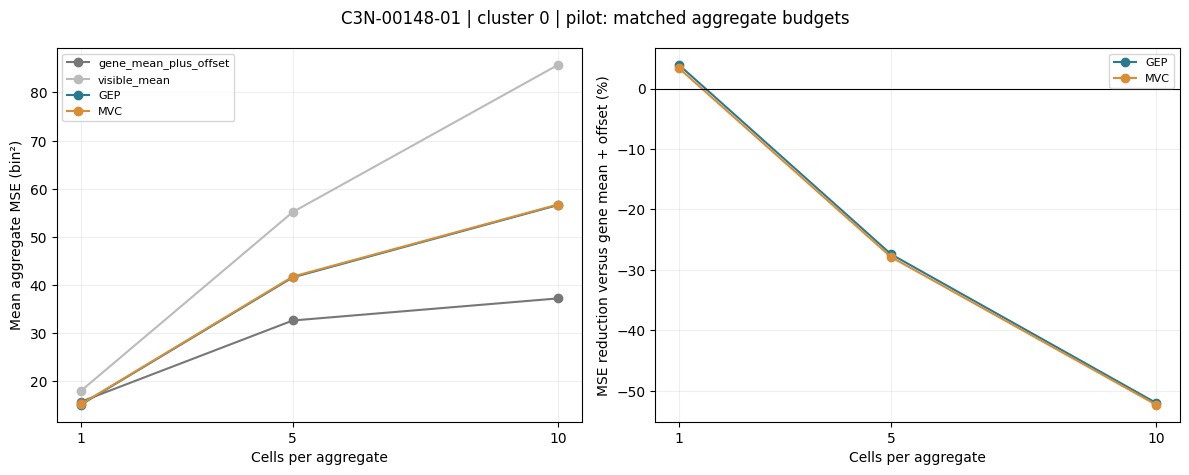

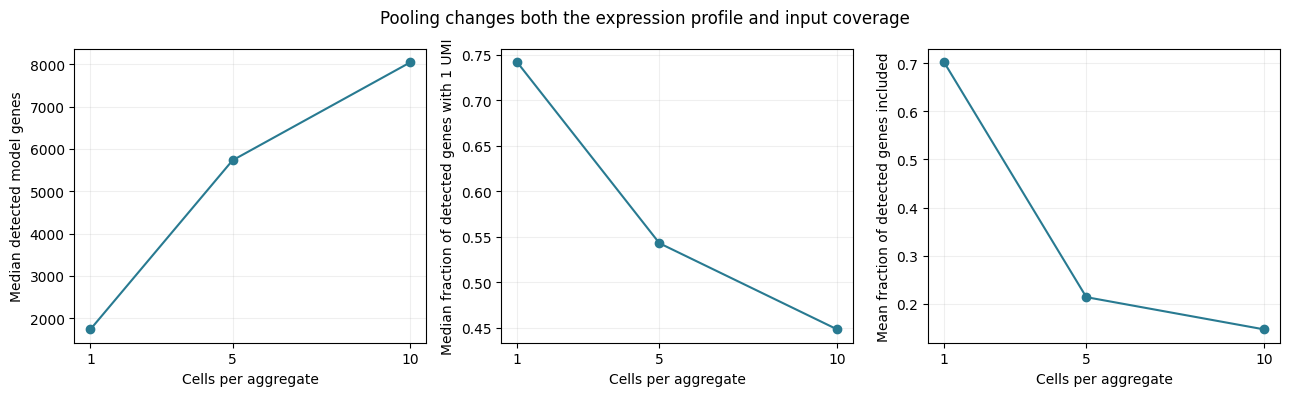

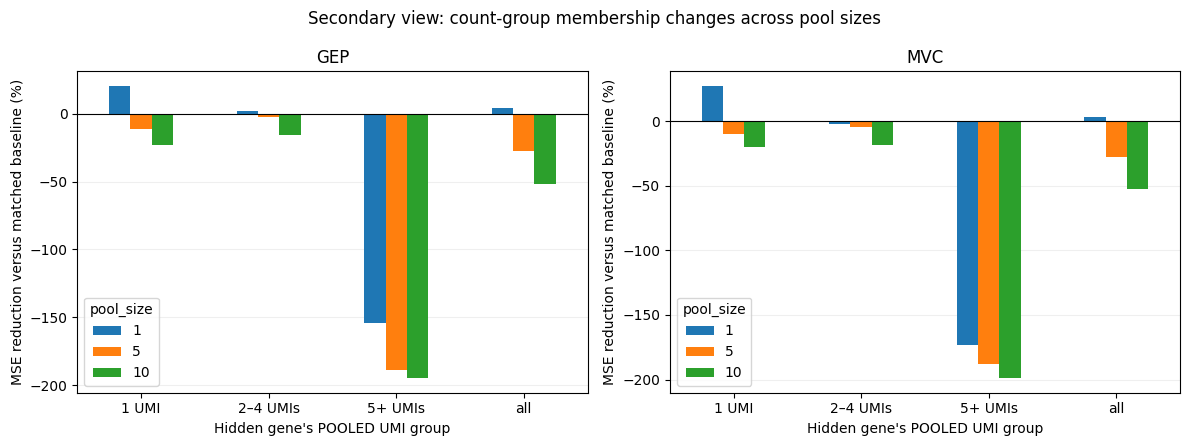

Figures: /home/akash1/scgpt-cna/aggregation_pilot/results/20261110T180438530299Z_pilot/figures


In [10]:
# 10 — Figures: primary overall loss/gain and changes in aggregate profiles.
import matplotlib.pyplot as plt

fig_dir = RUN_DIR / "figures"
fig_dir.mkdir(exist_ok=True)
sizes = sorted(map(int, aggregation_summary["pool_size"].unique()))
methods = ["gene_mean_plus_offset", "visible_mean", "GEP", "MVC"]
colors = ["#777777", "#BBBBBB", "#287A91", "#D98E36"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
overall = aggregation_summary.loc[aggregation_summary["count_group"].eq("all")]
for method, color in zip(methods, colors):
    part = overall.loc[overall["method"].eq(method)].set_index("pool_size").reindex(sizes)
    axes[0].plot(sizes, part["mean_MSE"], marker="o", label=method, color=color)
for head, color in [("GEP", colors[2]), ("MVC", colors[3])]:
    part = overall.loc[overall["method"].eq(head)].set_index("pool_size").reindex(sizes)
    axes[1].plot(sizes, part["percent_MSE_reduction"], marker="o", label=head, color=color)
axes[1].axhline(0, color="black", linewidth=.8)
axes[0].set_ylabel("Mean aggregate MSE (bin²)")
axes[1].set_ylabel("MSE reduction versus gene mean + offset (%)")
for ax in axes:
    ax.set_xlabel("Cells per aggregate"); ax.set_xticks(sizes)
    ax.grid(alpha=.2); ax.legend(fontsize=8)
fig.suptitle(f"{SOURCE_SAMPLE_ID} | cluster {selected_cluster} | {MODE}: matched aggregate budgets")
fig.tight_layout()
fig.savefig(fig_dir / "aggregation_overall_loss_and_gain.png", dpi=200, bbox_inches="tight")
fig.savefig(fig_dir / "aggregation_overall_loss_and_gain.pdf", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
profiles = pool_profiles.set_index("pool_size").reindex(sizes)
for ax, column, label in zip(axes,
    ["median_model_genes", "median_singleton_fraction", "included_gene_fraction"],
    ["Median detected model genes", "Median fraction of detected genes with 1 UMI", "Mean fraction of detected genes included"]):
    ax.plot(sizes, profiles[column], marker="o", color="#287A91")
    ax.set_xlabel("Cells per aggregate"); ax.set_xticks(sizes); ax.set_ylabel(label); ax.grid(alpha=.2)
fig.suptitle("Pooling changes both the expression profile and input coverage")
fig.tight_layout()
fig.savefig(fig_dir / "aggregation_profile_changes.png", dpi=200, bbox_inches="tight")
fig.savefig(fig_dir / "aggregation_profile_changes.pdf", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
group_order = ["1 UMI", "2–4 UMIs", "5+ UMIs", "all"]
for ax, head in zip(axes, ["GEP", "MVC"]):
    table = aggregation_summary.loc[aggregation_summary["method"].eq(head)].pivot(
        index="count_group", columns="pool_size", values="percent_MSE_reduction").reindex(index=group_order, columns=sizes)
    table.plot.bar(ax=ax, rot=0)
    ax.axhline(0, color="black", linewidth=.8)
    ax.set_title(head); ax.set_xlabel("Hidden gene's POOLED UMI group")
    ax.set_ylabel("MSE reduction versus matched baseline (%)"); ax.grid(axis="y", alpha=.2); ax.set_axisbelow(True)
fig.suptitle("Secondary view: count-group membership changes across pool sizes")
fig.tight_layout()
fig.savefig(fig_dir / "aggregation_count_group_gains.png", dpi=200, bbox_inches="tight")
plt.show()
print("Figures:", fig_dir)


In [11]:
# 11 — Standalone results reload; no checkpoint, raw counts or earlier cells required.
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.home() / "scgpt-cna"
RESULTS_ROOT = ROOT / "aggregation_pilot/results"
MODE_TO_LOAD = "pilot"        # Change to "full" after a completed full run.
RUN_TO_LOAD = None            # Or Path("/absolute/timestamped_run_directory")
if RUN_TO_LOAD is None:
    pointer = RESULTS_ROOT / f"latest_{MODE_TO_LOAD}_run.json"
    assert pointer.is_file(), "No completed-run pointer; finish cell 9 or specify RUN_TO_LOAD."
    RUN_DIR = Path(json.loads(pointer.read_text())["run_dir"])
else:
    RUN_DIR = Path(RUN_TO_LOAD)
saved_manifest = json.loads((RUN_DIR / "run_manifest.json").read_text())
MODE = saved_manifest["mode"]
SOURCE_SAMPLE_ID = saved_manifest["source_sample_id"]
selected_cluster = str(saved_manifest["selected_cluster"])
aggregation_summary = pd.read_csv(RUN_DIR / "aggregation_summary.csv")
aggregate_scores = pd.read_csv(RUN_DIR / "scores_by_aggregate.csv")
pool_profiles = pd.read_csv(RUN_DIR / "pool_profiles.csv")
context_summary = pd.read_csv(RUN_DIR / "context_comparison.csv")
coverage = pd.read_csv(RUN_DIR / "query_coverage.csv")
print("Loaded:", RUN_DIR)
display(aggregation_summary.loc[aggregation_summary["count_group"].eq("all"), [
    "pool_size", "method", "n_cells", "mean_MSE", "mean_MSE_gain", "percent_MSE_reduction"
]].round(3))
display(pool_profiles.round(3))
print("Plotting cell 10 can now run. No inference was performed.")


Loaded: /home/akash1/scgpt-cna/aggregation_pilot/results/20261110T180438530299Z_pilot


,pool_size,method,n_cells,mean_MSE,mean_MSE_gain,percent_MSE_reduction
24,1,GEP,8,15.170,0.616,3.899
25,1,GEP_shuffled,8,15.678,0.107,0.681
26,1,MVC,8,15.257,0.529,3.350
27,1,MVC_shuffled,8,15.698,0.088,0.556
28,1,gene_mean,8,17.461,-1.676,-10.617
29,1,gene_mean_plus_offset,8,15.786,0.000,0.000
30,1,reference_constant,8,19.660,-3.874,-24.544
31,1,visible_mean,8,18.022,-2.236,-14.168
56,5,GEP,8,41.620,-8.960,-27.432
57,5,GEP_shuffled,8,47.304,-14.643,-44.833


,pool_size,n_evaluated_pools,median_counts,median_model_genes,median_singleton_fraction,median_occupied_bins,median_dominant_bin_fraction,median_largest_source_share,median_pct_counts_mt,included_gene_fraction,visible_count_fraction,included_count_fraction,target_std
0,1,8,3283.5,1737.5,0.742,5.5,0.742,1.000,0.161,0.701,0.541,0.690,4.134
1,5,8,16431.5,5732.0,0.543,9.0,0.543,0.292,0.224,0.214,0.173,0.217,7.418
2,10,8,32849.0,8046.5,0.448,12.0,0.448,0.159,0.209,0.147,0.114,0.146,9.229


Plotting cell 10 can now run. No inference was performed.
